In [29]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find all patient records
files = sorted(Path("../data/raw/set-a").rglob("*.txt"))

print("Number of files:", len(files))
print("First file:", files[0] if files else "None")

# Read a sample patient
if files:
    patient = pd.read_csv(files[0])
    print(patient.head(10))
    print(patient["Parameter"].value_counts().head(15))


Number of files: 4000
First file: ../data/raw/set-a/132539.txt
    Time  Parameter      Value
0  00:00   RecordID  132539.00
1  00:00        Age      54.00
2  00:00     Gender       0.00
3  00:00     Height      -1.00
4  00:00    ICUType       4.00
5  00:00     Weight      -1.00
6  00:07        GCS      15.00
7  00:07         HR      73.00
8  00:07  NIDiasABP      65.00
9  00:07      NIMAP      92.33
Parameter
RespRate      42
Urine         38
HR            37
NIDiasABP     34
NIMAP         34
NISysABP      34
Temp          14
GCS           13
HCT            3
BUN            2
Creatinine     2
Glucose        2
HCO3           2
Mg             2
Platelets      2
Name: count, dtype: int64


In [30]:

records = []
empty_files = 0

for file in files:
    df = pd.read_csv(file)
    df = df[df["Parameter"].isin(["MAP", "NIMAP"])].copy()

    if df.empty:
        empty_files += 1
        continue

    df["RecordID"] = file.stem

    time = df["Time"].str.split(":", expand=True)
    df["hour"] = time[0].astype(float) + time[1].astype(float) / 60
    df["Value"] = pd.to_numeric(df["Value"], errors="coerce")

    records.append(df[["RecordID", "hour", "Parameter", "Value"]])

bp = pd.concat(records, ignore_index=True)

print(f"Patients with BP data: {bp['RecordID'].nunique()}")
print(f"Patients without BP data: {empty_files}")
print(f"Total measurements: {len(bp)}")
print(bp["Parameter"].value_counts())


Patients with BP data: 3937
Patients without BP data: 63
Total measurements: 242631
Parameter
MAP      145760
NIMAP     96871
Name: count, dtype: int64


## Exploring measurement frequency 
Between NIMAP (non-invasive mean arterial pressure) and MAP.

In [31]:

bp = bp.sort_values(["RecordID", "Parameter", "hour"])

# Time between consecutive measurements of the same type
bp["time_gap"] = (
    bp.groupby(["RecordID", "Parameter"])["hour"].diff()
)

print(
    bp.groupby("Parameter")["time_gap"]
    .describe()
    .round(2)
)


              count  mean  std   min   25%  50%  75%   max
Parameter                                                 
MAP        142968.0  0.74  0.6  0.00  0.25  1.0  1.0  37.5
NIMAP       93390.0  1.13  2.2  0.02  0.50  1.0  1.0  46.5


# What's missing in the data?

In [32]:
counts = (
    bp.groupby(["RecordID", "Parameter"])
    .size()
    .unstack(fill_value=0)
)

print(counts.describe())

print(
    "Patients with at least 5 NIMAP readings:",
    (counts.get("NIMAP", pd.Series(0, index=counts.index)) >= 5).sum()
)

print(
    "Patients with at least 5 MAP readings:",
    (counts.get("MAP", pd.Series(0, index=counts.index)) >= 5).sum()
)


Parameter          MAP        NIMAP
count      3937.000000  3937.000000
mean         37.023114    24.605283
std          30.025746    20.419872
min           0.000000     0.000000
25%           0.000000     5.000000
50%          43.000000    21.000000
75%          59.000000    43.000000
max         187.000000   122.000000
Patients with at least 5 NIMAP readings: 2990
Patients with at least 5 MAP readings: 2733


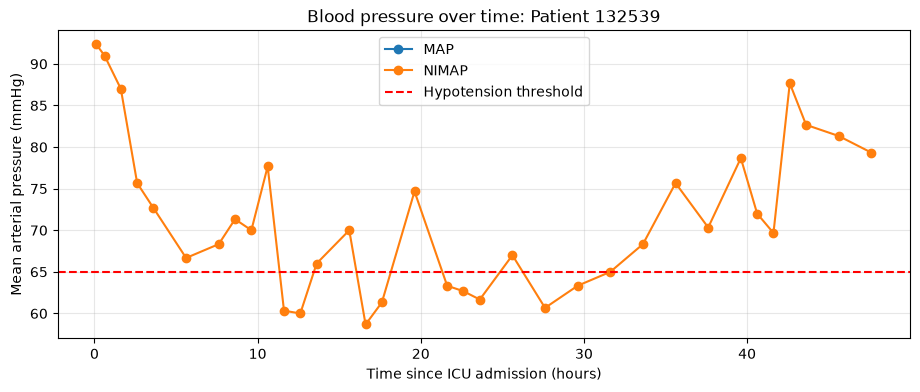

In [15]:

import matplotlib.pyplot as plt

patient_id = "132539"
patient = bp[bp["RecordID"] == patient_id]

plt.figure(figsize=(11, 4))

for variable in ["MAP", "NIMAP"]:
    subset = patient[patient["Parameter"] == variable]

    plt.plot(
        subset["hour"],
        subset["Value"],
        marker="o",
        label=variable
    )

plt.axhline(
    65, color="red", linestyle="--",
    label="Hypotension threshold"
)

plt.xlabel("Time since ICU admission (hours)")
plt.ylabel("Mean arterial pressure (mmHg)")
plt.title(f"Blood pressure over time: Patient {patient_id}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## For assignment: What's wrong with the data?

In [16]:

import pandas as pd
import numpy as np

# Make sure bp has numeric values
bp["Value"] = pd.to_numeric(bp["Value"], errors="coerce")

# Count invalid values
print("Missing numeric values:", bp["Value"].isna().sum())
print("Nonpositive values:", (bp["Value"] <= 0).sum())

# Flag potentially implausible values for inspection
# These are exploratory thresholds, not clinical exclusion rules.
print(
    "Values outside 20-200 mmHg:",
    ((bp["Value"] < 20) | (bp["Value"] > 200)).sum()
)

# How many patients have both types?
counts = (
    bp.groupby(["RecordID", "Parameter"])
    .size()
    .unstack(fill_value=0)
)

both = (counts["MAP"] > 0) & (counts["NIMAP"] > 0)

print("Patients with both:", both.sum())
print("MAP only:", ((counts["MAP"] > 0) & (counts["NIMAP"] == 0)).sum())
print("NIMAP only:", ((counts["MAP"] == 0) & (counts["NIMAP"] > 0)).sum())

# Check duplicate observations
duplicates = bp.duplicated(
    subset=["RecordID", "hour", "Parameter"]
).sum()

print("Duplicate patient-time-modality combinations:", duplicates)


Missing numeric values: 0
Nonpositive values: 75
Values outside 20-200 mmHg: 362
Patients with both: 2336
MAP only: 456
NIMAP only: 1145
Duplicate patient-time-modality combinations: 1864


In [17]:

keys = ["RecordID", "hour", "Parameter"]

duplicate_groups = (
    bp.groupby(keys)
    .agg(
        n_readings=("Value", "size"),
        n_unique=("Value", "nunique"),
        min_value=("Value", "min"),
        max_value=("Value", "max")
    )
    .reset_index()
)

duplicates = duplicate_groups[
    duplicate_groups["n_readings"] > 1
]

print("Duplicate groups:", len(duplicates))

print(
    "Groups with conflicting values:",
    (duplicates["n_unique"] > 1).sum()
)

print("\nExamples:")
print(duplicates.head(10))


Duplicate groups: 1864
Groups with conflicting values: 1864

Examples:
     RecordID       hour Parameter  n_readings  n_unique  min_value  max_value
5615   132781  24.183333       MAP           2         2       67.0       69.0
5616   132781  24.433333       MAP           2         2       89.0       90.0
5617   132781  24.683333       MAP           2         2       96.0       97.0
5618   132781  24.850000       MAP           2         2      103.0      104.0
5619   132781  24.933333       MAP           2         2      108.0      109.0
5620   132781  25.100000       MAP           2         2       57.0       58.0
5621   132781  25.183333       MAP           2         2      123.0      127.0
5622   132781  25.266667       MAP           2         2       64.0       65.0
5623   132781  25.433333       MAP           2         2       76.0       77.0
5624   132781  25.516667       MAP           2         2       93.0       94.0


In [18]:

print("Lowest values:")
print(
    bp.nsmallest(15, "Value")[
        ["RecordID", "hour", "Parameter", "Value"]
    ]
)

print("\nHighest values:")
print(
    bp.nlargest(15, "Value")[
        ["RecordID", "hour", "Parameter", "Value"]
    ]
)

print("\nNonpositive values by modality:")
print(
    bp[bp["Value"] <= 0]
    .groupby(["Parameter", "Value"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)


Lowest values:
      RecordID       hour Parameter  Value
1836    132614   3.283333       MAP    0.0
11142   133017   1.950000       MAP    0.0
21438   133430   7.633333     NIMAP    0.0
26866   133659  31.116667     NIMAP    0.0
28028   133718  21.250000     NIMAP    0.0
28053   133718  28.000000     NIMAP    0.0
32395   133933   4.150000       MAP    0.0
38623   134167  13.933333     NIMAP    0.0
41617   134299   2.400000     NIMAP    0.0
42209   134318   5.466667     NIMAP    0.0
44008   134402  28.350000     NIMAP    0.0
51980   134709  21.350000     NIMAP    0.0
54902   134835   3.200000       MAP    0.0
57738   134965  25.516667       MAP    0.0
73501   135603   0.483333       MAP    0.0

Highest values:
       RecordID       hour Parameter  Value
174556   139776   8.316667       MAP  300.0
209653   141283   2.250000       MAP  300.0
63013    135200  39.950000       MAP  299.0
146822   138682   8.450000       MAP  295.0
180845   140049  19.966667       MAP  295.0
190319   140465 

In [19]:

from pathlib import Path

clean = bp.copy()

# Preserve an audit trail of potentially extreme values
clean["extreme_flag"] = (
    (clean["Value"] < 20) |
    (clean["Value"] > 200)
)

# Remove nonpositive readings
clean = clean[
    clean["Value"].notna() &
    (clean["Value"] > 0)
].copy()

# Aggregate duplicate observations
clean = (
    clean.groupby(
        ["RecordID", "hour", "Parameter"],
        as_index=False
    )
    .agg(
        Value=("Value", "median"),
        n_original=("Value", "size"),
        extreme_flag=("extreme_flag", "max")
    )
)

clean = clean.sort_values(
    ["RecordID", "Parameter", "hour"]
)

Path("data/clean").mkdir(parents=True, exist_ok=True)

clean.to_parquet(
    "data/clean/blood_pressure.parquet",
    index=False
)

print("Original measurements:", len(bp))
print("Cleaned measurements:", len(clean))
print("Removed/aggregated:", len(bp) - len(clean))
print("Patients remaining:", clean["RecordID"].nunique())


Original measurements: 242631
Cleaned measurements: 240692
Removed/aggregated: 1939
Patients remaining: 3937


In [20]:

nimap = clean[
    clean["Parameter"] == "NIMAP"
].copy()

nimap = nimap.sort_values(
    ["RecordID", "hour"]
)

nimap["next_hour"] = (
    nimap.groupby("RecordID")["hour"].shift(-1)
)

nimap["next_value"] = (
    nimap.groupby("RecordID")["Value"].shift(-1)
)

nimap["gap"] = (
    nimap["next_hour"] - nimap["hour"]
)

# First exploratory definition:
# next observation 45-75 minutes later
eligible = nimap[
    nimap["gap"].between(0.75, 1.25)
].copy()

print("Eligible forecast pairs:", len(eligible))
print(
    "Patients represented:",
    eligible["RecordID"].nunique()
)

print("\nTime gap distribution:")
print(eligible["gap"].describe())

print(
    "\nObserved hypotension prevalence:",
    (eligible["next_value"] < 65).mean()
)


Eligible forecast pairs: 60168
Patients represented: 2999

Time gap distribution:
count    60168.000000
mean         0.993752
std          0.046578
min          0.750000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.250000
Name: gap, dtype: float64

Observed hypotension prevalence: 0.1930428134556575


In [24]:

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 'eligible' is the DataFrame you just created.
# It contains RecordID, hour, Value, next_hour, next_value, gap.

# Split by patient, NOT by individual measurements
patient_ids = eligible["RecordID"].astype(str).to_numpy(dtype=str)
patient_ids = np.unique(patient_ids)

train_ids, temp_ids = train_test_split(
    patient_ids,
    test_size=0.30,
    random_state=42
)

val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=42
)

train = eligible[eligible["RecordID"].isin(train_ids)].copy()
val = eligible[eligible["RecordID"].isin(val_ids)].copy()
test = eligible[eligible["RecordID"].isin(test_ids)].copy()

print("Training pairs:", len(train))
print("Validation pairs:", len(val))
print("Testing pairs:", len(test))

print("Train patients:", len(train_ids))
print("Validation patients:", len(val_ids))
print("Test patients:", len(test_ids))

# Persistence: predict that the next BP equals the current BP
y_true = test["next_value"].to_numpy()
y_pred = test["Value"].to_numpy()

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print(f"\nPersistence MAE: {mae:.3f} mmHg")
print(f"Persistence RMSE: {rmse:.3f} mmHg")

# Hypotension classification
# Alert if predicted NIMAP < 65 mmHg
true_alert = (y_true < 65).astype(int)
pred_alert = (y_pred < 65).astype(int)

precision = precision_score(
    true_alert, pred_alert, zero_division=0
)
recall = recall_score(
    true_alert, pred_alert, zero_division=0
)
f1 = f1_score(
    true_alert, pred_alert, zero_division=0
)

print("\nHypotension alert metrics")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1:        {f1:.3f}")

print("\nConfusion matrix:")
print(confusion_matrix(true_alert, pred_alert))

# Save predictions
Path("results").mkdir(exist_ok=True)

results = test[
    ["RecordID", "hour", "next_hour", "gap"]
].copy()

results["actual"] = y_true
results["prediction"] = y_pred
results["actual_hypotension"] = true_alert
results["predicted_hypotension"] = pred_alert

results.to_csv(
    "results/nimap_persistence_test.csv",
    index=False
)


Training pairs: 41806
Validation pairs: 9302
Testing pairs: 9060
Train patients: 2099
Validation patients: 450
Test patients: 450

Persistence MAE: 7.595 mmHg
Persistence RMSE: 10.747 mmHg

Hypotension alert metrics
Precision: 0.585
Recall:    0.591
F1:        0.588

Confusion matrix:
[[6689  700]
 [ 684  987]]


In [25]:

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the cleaned NIMAP data
nimap = clean[clean["Parameter"] == "NIMAP"].copy()
nimap = nimap.sort_values(["RecordID", "hour"])

g = nimap.groupby("RecordID")

# Historical features
nimap["previous_nimap"] = g["Value"].shift(1)
nimap["previous_hour"] = g["hour"].shift(1)

nimap["change"] = (
    nimap["Value"] - nimap["previous_nimap"]
)

nimap["time_since_previous"] = (
    nimap["hour"] - nimap["previous_hour"]
)

nimap["mean_last_3"] = (
    g["Value"].transform(
        lambda s: s.rolling(3, min_periods=1).mean()
    )
)

nimap["std_last_3"] = (
    g["Value"].transform(
        lambda s: s.rolling(3, min_periods=2).std()
    )
)

# Use the exact same forecasting examples
features = nimap.merge(
    eligible[["RecordID", "hour", "next_value"]],
    on=["RecordID", "hour"],
    how="inner",
    validate="one_to_one"
)

features["last_nimap"] = features["Value"]

feature_cols = [
    "last_nimap",
    "previous_nimap",
    "change",
    "time_since_previous",
    "mean_last_3",
    "std_last_3",
    "hour"
]

train_ml = features[features["RecordID"].isin(train_ids)]
val_ml = features[features["RecordID"].isin(val_ids)]
test_ml = features[features["RecordID"].isin(test_ids)]

model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    random_state=42
)

model.fit(
    train_ml[feature_cols],
    train_ml["next_value"]
)

val_pred = model.predict(val_ml[feature_cols])
test_pred = model.predict(test_ml[feature_cols])

print("Validation MAE:",
      mean_absolute_error(val_ml["next_value"], val_pred))

print("Test MAE:",
      mean_absolute_error(test_ml["next_value"], test_pred))

print("Test RMSE:",
      np.sqrt(mean_squared_error(test_ml["next_value"], test_pred)))

print("Persistence Test MAE:", 7.595)


Validation MAE: 6.605019097993563
Test MAE: 6.8205886853193025
Test RMSE: 9.356049060924349
Persistence Test MAE: 7.595
